# Bank Marketing Data Audit and First Baseline

**Working question:** Can we prioritise customers likely to subscribe to a term deposit before a marketing call?

This notebook audits the development rows and compares logistic regression with a dummy classifier. Notebook 02 continues with the three models, tuning, ensemble and reserved holdout evaluation.

Source: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing). We use `bank-additional-full.csv`, not its smaller sample. The publisher's detailed column descriptions are retained in `data/raw/bank-additional-names.txt`.

In VS Code, select the project's `.venv` Python as the kernel. Then restart the kernel and run all cells in order.

In [1]:
from pathlib import Path
import platform
import sys
import pandas as pd
from IPython.display import display, Image

root = Path.cwd().resolve()
while not (root / "src" / "starter.py").exists():
    if root == root.parent:
        raise RuntimeError("Open this notebook from the Bank Marketing project or its notebooks folder.")
    root = root.parent
sys.path.insert(0, str(root / "src"))
from starter import load_raw, development_data, build_features, preprocessing, save_eda, validate_baselines
print("Python:", platform.python_version())

Python: 3.12.14


## 1 Dataset eligibility and development split

The labelled yes/no outcome makes binary classification an appropriate starting point. The bank's objective should be expressed in business terms, such as useful contacts per campaign budget; predicting a subscription is the corresponding ML objective. This dataset is historical and does not establish present-day banking performance.

The full file is ordered by date. Freeze the first 80% for development and the final 20% for later testing before exploring outcomes or trying transformations. The final holdout is not evaluated or used for model selection here. Without exact timestamps or customer IDs, source-order validation is an approximation and repeated-client leakage cannot be fully ruled out.

In [2]:
from bank_data import TOTAL

raw = load_raw(development_only=True)
development, split_manifest = development_data(raw, source_rows=TOTAL)
print(f"Original rows: {split_manifest['raw_rows']:,}; original input features: {split_manifest['raw_input_features']}")
display(pd.Series(split_manifest, name="value").to_frame())
display(development.head())

Original rows: 41,188; original input features: 20

,value
raw_rows,41188
raw_input_features,20
development_raw_rows,32950
development_clean_rows,32940
development_exact_duplicates_removed,10
test_start_source_row,32950
reserved_test_rows,8238
split_policy,First 80% development; last 20% final holdout;...
holdout_evaluated,False


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,source_row
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,1
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,3
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,4


## 2 Initial development data audit

Examine class imbalance, descriptive statistics, literal nulls and explicit `unknown` categories. The source names file explains that `unknown` represents missing categorical information. Therefore, no literal nulls does not mean no missing information.

Exact raw-row duplicates in development are removed provisionally, preserving chronological order. This assumption needs comparison later because different clients can share identical measurements.

In [3]:
summary = save_eda(development, split_manifest)
print("Development subscription rate:", f"{summary['development_positive_rate']:.2%}")
print("Exact development duplicates removed:", summary['development_exact_duplicates_removed'])
display(pd.read_csv(root / "results/metrics/development_missingness.csv", index_col=0))
display(pd.read_csv(root / "results/metrics/development_descriptive_statistics.csv", index_col=0))

Development subscription rate: 6.38%
Exact development duplicates removed: 10


,null_count,unknown_count,dtype
age,0,0,int64
job,0,266,str
marital,0,62,str
education,0,1321,str
default,0,8016,str
housing,0,781,str
loan,0,781,str
contact,0,0,str
month,0,0,str
day_of_week,0,0,str


,count,mean,std,min,25%,50%,75%,max
age,32940.0,40.027353,9.354247,18.000,33.000,39.000,47.000,95.000
duration,32940.0,255.988191,261.262849,0.000,100.000,175.000,314.000,4918.000
campaign,32940.0,2.671554,2.970490,1.000,1.000,2.000,3.000,56.000
pdays,32940.0,993.750880,72.033204,0.000,999.000,999.000,999.000,999.000
previous,32940.0,0.072890,0.274612,0.000,0.000,0.000,0.000,3.000
emp.var.rate,32940.0,0.650358,1.160220,-1.800,-0.100,1.100,1.400,1.400
cons.price.idx,32940.0,93.704244,0.480574,92.756,93.200,93.918,93.994,94.465
cons.conf.idx,32940.0,-40.637289,3.866694,-50.000,-42.700,-41.800,-36.400,-36.100
euribor3m,32940.0,4.269004,1.283825,1.299,4.191,4.864,4.962,5.045
nr.employed,32940.0,5195.140109,44.852791,5099.100,5191.000,5195.800,5228.100,5228.100


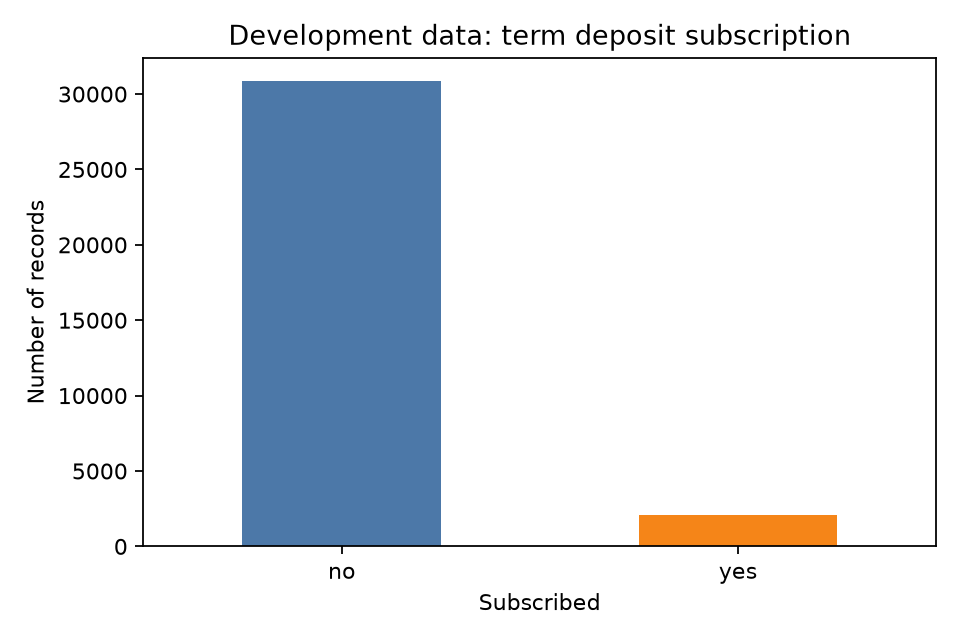

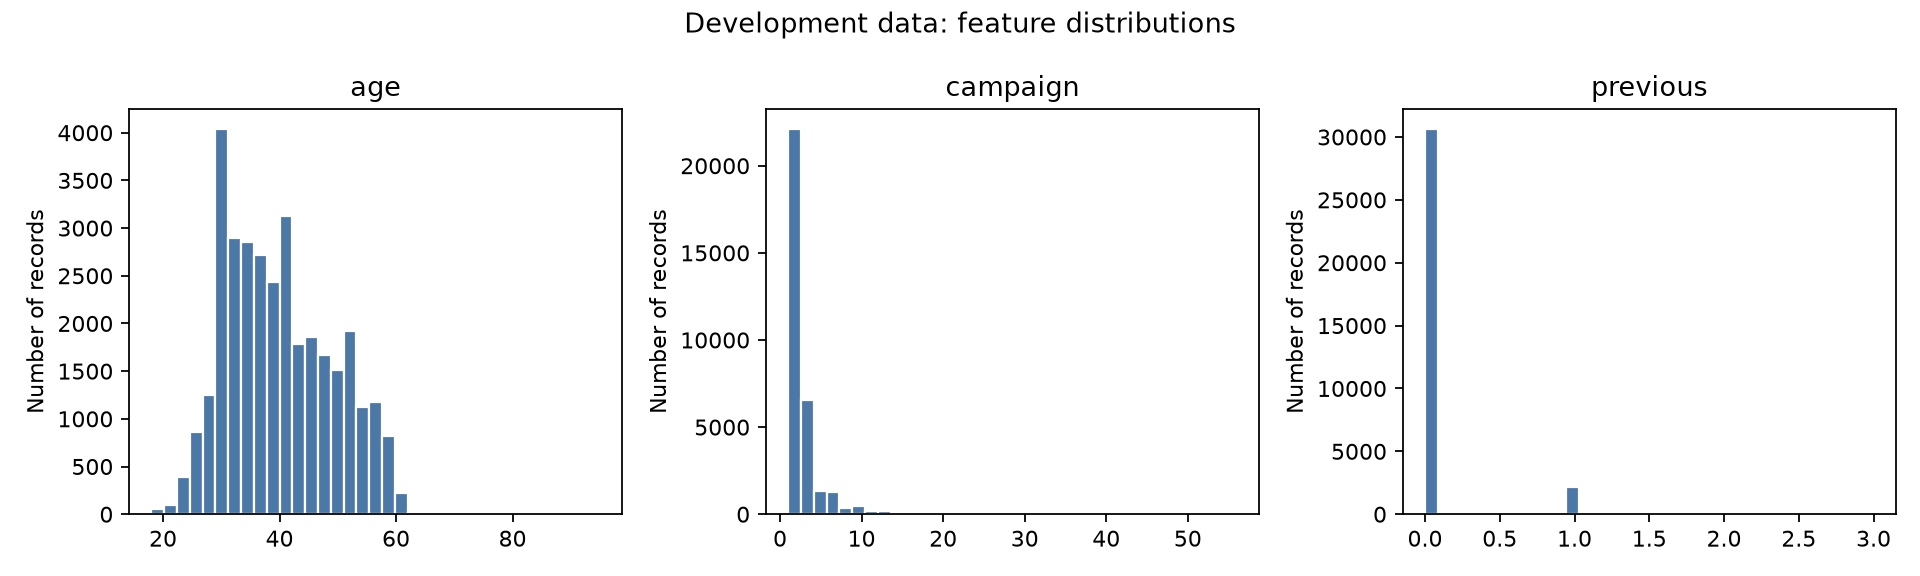

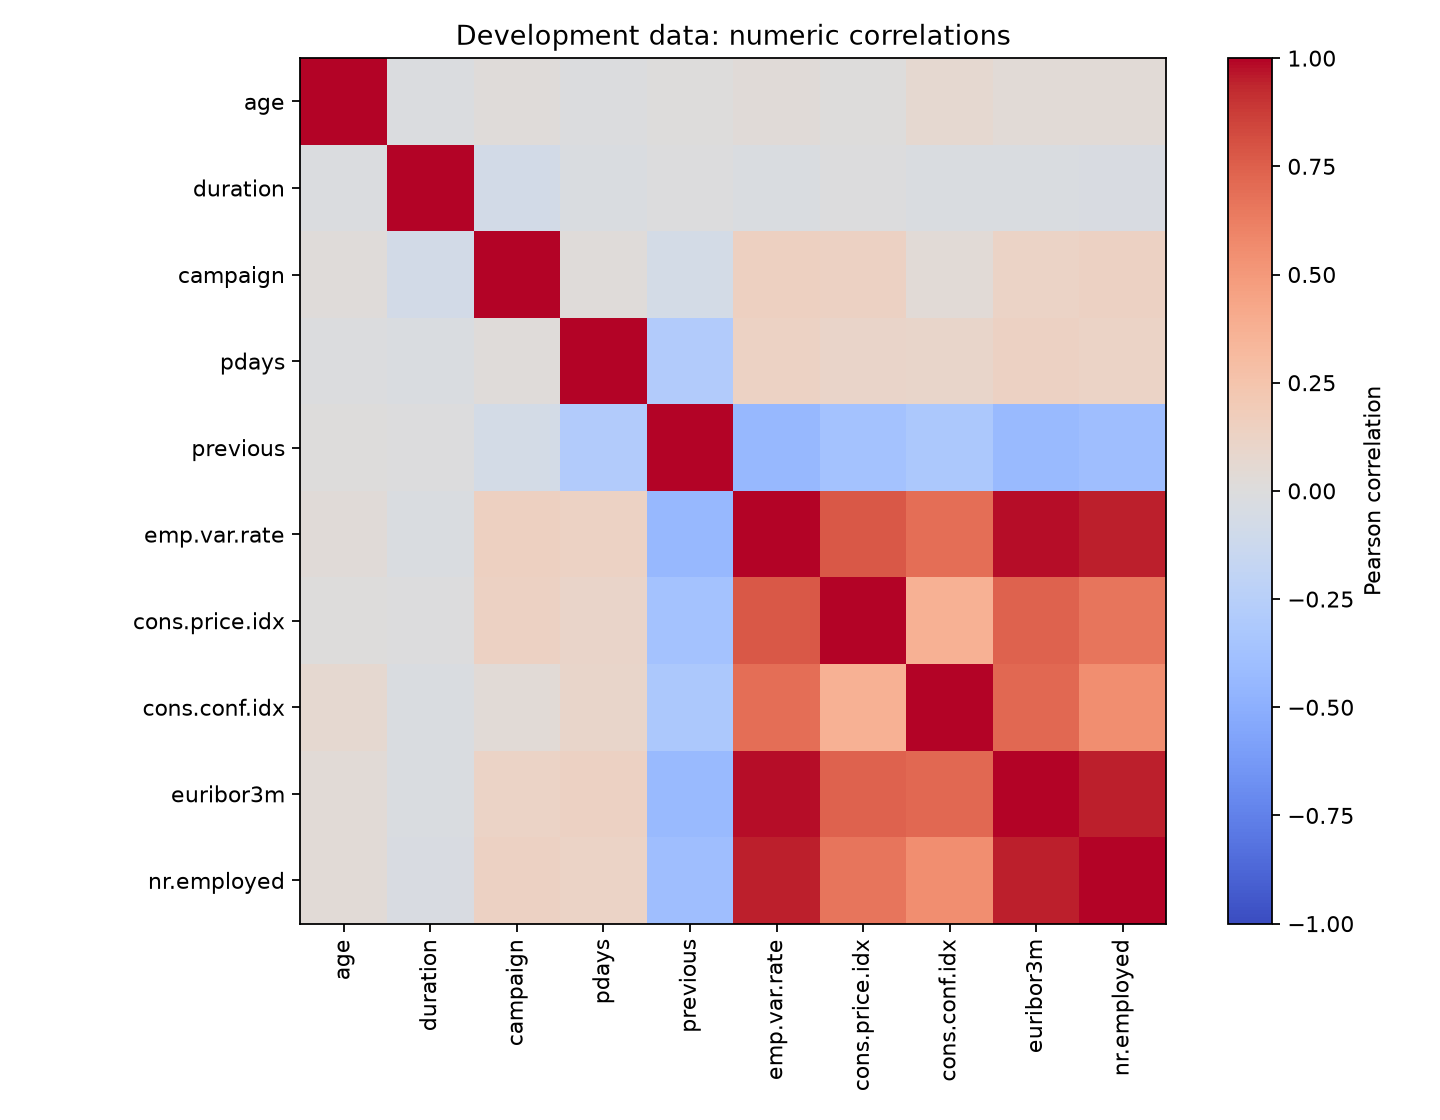

In [4]:
display(Image(filename=str(root / "results/figures/development_target_balance.png")))
display(Image(filename=str(root / "results/figures/development_distributions.png")))
display(Image(filename=str(root / "results/figures/development_correlations.png")))

**Interpretation prompts:** Which features are skewed? Which correlations may indicate redundant economic signals? Why does a positive subscription rate affect the meaning of accuracy? Are extreme ages or campaign counts errors, or plausible observations? Outlier flags are not a reason to delete rows automatically. The `pdays=999` sentinel also makes raw numeric summaries misleading until its domain meaning is handled.

Noise and inconsistencies need explicit investigation beyond these initial plots. Document what you can observe and what cannot be verified from the available fields.

In [5]:
display(pd.read_csv(root / "results/metrics/development_skewness.csv", index_col=0))
display(pd.read_csv(root / "results/metrics/development_outlier_flags.csv", index_col=0))

,skewness
age,0.476213
duration,3.319244
campaign,4.649121
pdays,-13.650617
previous,3.866144
emp.var.rate,-1.387592
cons.price.idx,-0.142358
cons.conf.idx,-0.173640
euribor3m,-1.719186
nr.employed,-1.371903


,iqr_flag_count
age,77
duration,2463
campaign,2143
pdays,174
previous,2275
emp.var.rate,0
cons.price.idx,0
cons.conf.idx,0
euribor3m,5258
nr.employed,5258


## 3 First preprocessing pipeline

- Drop `duration`: it is not known before the call and would undermine the intended use.
- Treat `pdays=999` as an unrecorded contact interval. The `pdays_recorded` indicator shows whether that interval was supplied. Some rows with `pdays=999` have a positive `previous` contact count.
- Preserve `unknown` categorical levels initially. One-hot encoding handles categorical features; unseen levels at validation time are ignored.
- Fit numeric median imputation and scaling inside each training fold. The pipeline ensures validation values do not determine these transformations.

This is the first approach to compare, not a claim that every choice is optimal. Review whether the remaining fields are available at the intended prediction time. In particular, `campaign` includes the current contact; deployment must define its input as the known planned contact number. Economic indicators may be revised after their original release, so point-in-time availability is another limitation.

In [6]:
X, y = build_features(development)
assert "duration" not in X and "source_row" not in X and "y" not in X
assert X.index.equals(y.index)
print("Model input columns:", X.columns.tolist())
display(preprocessing(X))
processed = root / "data/processed"
processed.mkdir(parents=True, exist_ok=True)
cleaned = X.copy()
cleaned["y"] = y
cleaned.index.name = "source_row"
cleaned.to_csv(processed / "development_cleaned.csv")

Model input columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pdays_recorded']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

## 4 Dummy and logistic regression baseline

Use three expanding-window cross-validation folds on development data. The dummy classifier represents predictions based on the training prevalence alone; it is not one of the three required substantive models. Logistic regression is the first substantive candidate. Its class weighting is a preliminary imbalance strategy to compare with unweighted fitting later.

Average precision is the initial primary ranking metric. Its reference level depends on the positive prevalence in each validation fold, so inspect the fold table as well as averages. Precision, recall and F1 currently use default prediction thresholds. These are development validation scores, not final test results or deployment claims.

In [7]:
baseline_summary = validate_baselines(X, y)
display(pd.read_csv(root / "results/metrics/cross_validation_folds.csv"))
display(baseline_summary.round(4))
display(pd.read_csv(root / "results/metrics/baseline_fold_results.csv").round(4))

,fold,train_rows,validation_rows,train_last_source_row,validation_first_source_row,validation_positive_rate
0,1,8235,8235,8235,8236,0.054281
1,2,16470,8235,16472,16473,0.058531
2,3,24705,8235,24711,24712,0.110747


,fit_time_mean,fit_time_std,score_time_mean,score_time_std,test_average_precision_mean,test_average_precision_std,test_roc_auc_mean,test_roc_auc_std,test_balanced_accuracy_mean,test_balanced_accuracy_std,test_precision_mean,test_precision_std,test_recall_mean,test_recall_std,test_f1_mean,test_f1_std,test_accuracy_mean,test_accuracy_std
model,,,,,,,,,,,,,,,,,,
dummy_prior,0.0986,0.0299,0.0630,0.0023,0.0745,0.0314,0.5000,0.0000,0.5000,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.9255,0.0314
logistic_regression,0.2002,0.1063,0.0689,0.0047,0.0708,0.0288,0.4787,0.0297,0.4761,0.0303,0.0585,0.0101,0.577,0.4695,0.0877,0.0203,0.3711,0.3843


,model,fold,fit_time,score_time,test_average_precision,test_roc_auc,test_balanced_accuracy,test_precision,test_recall,test_f1,test_accuracy
0,dummy_prior,1,0.1274,0.0606,0.0543,0.5000,0.5000,0.0000,0.0000,0.0000,0.9457
1,dummy_prior,2,0.0677,0.0632,0.0585,0.5000,0.5000,0.0000,0.0000,0.0000,0.9415
2,dummy_prior,3,0.1008,0.0653,0.1107,0.5000,0.5000,0.0000,0.0000,0.0000,0.8893
3,logistic_regression,1,0.0892,0.0667,0.0529,0.5093,0.5041,0.0547,0.9776,0.1036,0.0820
4,logistic_regression,2,0.2105,0.0743,0.0555,0.4500,0.4440,0.0508,0.6929,0.0947,0.2242
5,logistic_regression,3,0.3010,0.0656,0.1040,0.4769,0.4802,0.0700,0.0603,0.0648,0.8072


## 5 Continue to the final experiments

Open `02_model_experiments.ipynb` to see the feature comparison, tuned models, ensemble, holdout evaluation and descriptive checks used in the report.

**Explain aloud:** Why can accuracy be misleading? Why is duration excluded? Why must imputation and scaling be fitted within each fold? What does the prior-only dummy tell you when subscription rates differ across the folds?